# Tutorial 4: the variational quantum eigensolver (Qiskit)

<!-- BEGIN SOLUTION (remove) -->
> **This version includes the solutions.** Try each exercise yourself before reading its solution.

<!-- END SOLUTION -->
*Near-term Quantum Computing 2026-2027, tutorial 4.*

In Lecture 4, we turned the adiabatic circuit into a variational one, the Hamiltonian variational
ansatz (HVA), whose angles a classical optimiser chooses to minimise the measured energy. In this
tutorial, we first run the adiabatic circuit itself, and then this variational quantum eigensolver (VQE) for the TFIM chain of the lecture,
with every energy estimated from shots, as on a quantum computer. We compare two optimisers by
what they cost in shots, and look at what gate noise does to the result.

In this tutorial you will learn to:

1. build parametrised circuits in Qiskit, and write the energy as a function of their angles;
2. minimise it with an optimiser from scipy, and read and check its result;
3. see how the accuracy of the adiabatic circuit depends on its total time and its step length;
4. compute gradients with the parameter-shift rule, and compare optimisers by their total cost
   in shots;
5. find conceptual mistakes in a VQE run and its report.

**How this tutorial works.** As in the previous tutorials:

- **Part A** (about 40 minutes): we code together. Type the code yourself in the empty cells.
- **Part B**: exercises, at home, alone or in pairs. Exercises 1, 2 and 3 are the core; 4 and 5
  go further.
- Questions marked **(paper)** are for pen and paper: answer them *before* running the code.

**Conventions**, as in Lecture 4: the transverse-field Ising model (TFIM) on an open chain,
$H = -J\sum_i Z_iZ_{i+1} - h\sum_i X_i$, with $J = 1$ and $h = 0.5$ (Tutorial 3 used $h = 1$). We
use $n = 4$ qubits instead of the 8 of the notes, so that every optimisation takes seconds. The
qubits are numbered from 0, as in Qiskit. As in Tutorial 3, an energy estimate with "$N$ shots"
uses $N$ shots in each of the two measurement settings, so $2N$ shots in all.

Documentation: [Qiskit API reference](https://quantum.cloud.ibm.com/docs/en/api/qiskit),
[`ParameterVector`](https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.circuit.ParameterVector),
[`scipy.optimize.minimize`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.minimize.html)
and its [COBYLA method](https://docs.scipy.org/doc/scipy/reference/optimize.minimize-cobyla.html).
In a notebook, a cell with `minimize?` shows the documentation of `minimize`, and the same works
for any function.

## Setup

In Google Colab, run the next cell first to install the packages. If you work on your own
computer, install the same packages in your Python environment instead.

In [1]:
%pip install -q "qiskit~=2.5.2" "qiskit-aer~=0.18.0" "scipy>=1.16" pylatexenc

Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector, SparsePauliOp
from qiskit_aer import AerSimulator

simulator = AerSimulator()
J, h = 1.0, 0.5

The next cell is given: the functions of Tutorial 3 that we reuse. `tfim(n, J, h)` builds the
Hamiltonian. `measure_energy(circuit, shots, J, h)` estimates $\langle H\rangle$ of the state that
`circuit` prepares, from `shots` shots in each of the two settings, and returns the estimate and
its standard error; it uses `signs` and `group_values`.

In [3]:
def tfim(n, J, h):
    """The TFIM on an open chain of n qubits, as a SparsePauliOp."""
    terms = []
    for i in range(n - 1):                      # bonds
        terms.append(("ZZ", [i, i + 1], -J))
    for i in range(n):                          # fields
        terms.append(("X", [i], -h))
    return SparsePauliOp.from_sparse_list(terms, num_qubits=n)


def signs(bitstring):
    """The outcomes of one shot as signs: signs(bitstring)[q] is +1 or -1 for qubit q."""
    return [1 - 2 * int(b) for b in bitstring[::-1]]   # reversed: Qiskit writes qubit 0 last


def group_values(counts, setting, J, h):
    """One value per shot: s_Z if setting is "Z", s_X if setting is "X"."""
    values = []
    for bitstring, count in counts.items():
        s = signs(bitstring)
        n = len(s)
        if setting == "Z":
            total = 0
            for i in range(n - 1):
                total += s[i] * s[i + 1]
            value = -J * total
        else:
            value = -h * sum(s)
        values += [value] * count
    return np.array(values)


def measure_energy(state_circuit, shots, J, h):
    """Estimate <H> of the TFIM from `shots` shots in each of the two settings.

    Returns the estimate and its standard error."""
    n = state_circuit.num_qubits
    energy, variance = 0, 0
    for setting in ["Z", "X"]:
        circuit = state_circuit.copy()
        if setting == "X":
            circuit.h(range(n))
        circuit.measure_all()
        counts = simulator.run(circuit, shots=shots).result().get_counts()
        values = group_values(counts, setting, J, h)
        energy += values.mean()
        variance += values.var() / shots
    return energy, np.sqrt(variance)

Our chain has 4 qubits. Its ground-state energy $E_0$ is the lowest eigenvalue of the matrix of
$H$ (exact diagonalisation, as in Tutorial 3). A VQE is meant for problems where $E_0$ is not
known; on a small instance, we compute it to check the method (notes, section ["The variational
quantum eigensolver"](https://stefanopolla.github.io/course-testing/L4-ground-states.html#sec-vqe-loop)).

In [4]:
n = 4
hamiltonian = tfim(n, J, h)
E0 = np.linalg.eigvalsh(hamiltonian.to_matrix())[0]
print("E0 =", round(E0, 4))

E0 = -3.427


## Part A: coding together

### A1. Parametrised circuits

The HVA with $p$ layers (notes, section ["The Hamiltonian variational ansatz"](https://stefanopolla.github.io/course-testing/L4-ground-states.html#sec-hva)) starts from
$|{+}\cdots{+}\rangle$ and applies, in layer $k$, $R_{ZZ}(\gamma_k)$ on every bond and
$R_X(\beta_k)$ on every qubit: a Trotter step of Tutorial 3 with free angles. Its $2p$ angles are
$\theta = (\gamma_1, \beta_1, \dots, \gamma_p, \beta_p)$.

An optimiser tries many values of these angles. Instead of building a new circuit for each, we
build the circuit once with *parameters*, symbols that stand for angles we choose later.
`ParameterVector("theta", m)` creates $m$ of them, `theta[0]`, ..., `theta[m - 1]`, and we use
them wherever a gate needs an angle, for example `circuit.rx(theta[1], 0)`; the same parameter
can appear in several gates. `circuit.assign_parameters(values)` then returns a copy of the
circuit with the numbers in `values` in place of `theta[0]`, `theta[1]`, ..., in this order.

Complete `hva_ansatz`, with the bonds in two layers as in `trotter_step` of Tutorial 3: `gamma` is
the angle of all the bond gates of layer `k`, and `beta` the angle of all its field gates.

In [5]:
from qiskit.circuit import ParameterVector


def hva_ansatz(n, p):
    """The HVA with p layers on n qubits; its parameters are (γ_1, β_1, ..., γ_p, β_p)."""
    theta = ParameterVector("theta", 2 * p)
    circuit = QuantumCircuit(n)
    circuit.h(range(n))                          # |+...+>
    for k in range(p):
        gamma = theta[2 * k]
        beta = theta[2 * k + 1]
        # BEGIN SOLUTION
        for i in range(0, n - 1, 2):             # bonds (0,1), (2,3), ...
            circuit.rzz(gamma, i, i + 1)
        for i in range(1, n - 1, 2):             # bonds (1,2), (3,4), ...
            circuit.rzz(gamma, i, i + 1)
        for i in range(n):                       # fields
            circuit.rx(beta, i)
        # END SOLUTION
    return circuit


print(hva_ansatz(n, 1).draw())

     ┌───┐               ┌──────────────┐                
q_0: ┤ H ├─■─────────────┤ Rx(theta[1]) ├────────────────
     ├───┤ │ZZ(theta[0]) └──────────────┘┌──────────────┐
q_1: ┤ H ├─■──────────────■──────────────┤ Rx(theta[1]) ├
     ├───┤                │ZZ(theta[0])  ├──────────────┤
q_2: ┤ H ├─■──────────────■──────────────┤ Rx(theta[1]) ├
     ├───┤ │ZZ(theta[0]) ┌──────────────┐└──────────────┘
q_3: ┤ H ├─■─────────────┤ Rx(theta[1]) ├────────────────
     └───┘               └──────────────┘                


We use $p = 3$ layers: `ansatz` is the circuit that we optimise in the rest of this tutorial.

In [6]:
p = 3
ansatz = hva_ansatz(n, p)
print("number of parameters:", ansatz.num_parameters)

number of parameters: 6


**The adiabatic schedule** is one point of the ansatz, and our starting point (notes, section
["The Hamiltonian variational ansatz"](https://stefanopolla.github.io/course-testing/L4-ground-states.html#sec-hva)). With $p$ Trotter steps of length $\delta = T/p$, layer $k$
has $\gamma_k = -2s_kJ\delta$ and $\beta_k = -2h\delta$, where $s_k = (k - \frac12)/p$ is the
middle of step $k = 1, \dots, p$.

**(paper)** What are the six angles for $p = 3$ and $T = 3$? Then run the next cell, where the
given function `schedule` computes them. (Python counts `k` from 0, so there the middle of step
`k` is `(k + 0.5) / p`.)

In [7]:
def schedule(p, T):
    """The angles (γ_1, β_1, ..., γ_p, β_p) of the adiabatic schedule: p Trotter steps up to time T."""
    dt = T / p
    angles = []
    for k in range(p):
        s = (k + 0.5) / p                        # the middle of step k
        angles += [-2 * s * J * dt, -2 * h * dt]
    return np.array(angles)


start = schedule(p, 3.0)
print("schedule angles:", np.round(start, 3))

schedule angles: [-0.333 -1.    -1.    -1.    -1.667 -1.   ]


<!-- BEGIN SOLUTION -->
**Solution.** $\delta = 1$ and $s_k = \frac16, \frac12, \frac56$, so
$\gamma_k = -\frac13, -1, -\frac53$, and $\beta_k = -1$ in every layer.
<!-- END SOLUTION -->

**The energy as a function of the angles.** In simulation, we compute the energy of the prepared
state exactly, as in Tutorial 3. Complete `energy_exact`: assign the angles to `ansatz`, and
compute $\langle H\rangle$ of its `Statevector`.

**(paper)** What is the energy at $\theta = 0$, where every gate of a layer is the identity?

In [8]:
def energy_exact(angles):
    """The exact energy of the state that `ansatz` prepares with these angles (simulation only)."""
    # BEGIN SOLUTION
    circuit = ansatz.assign_parameters(angles)
    return Statevector(circuit).expectation_value(hamiltonian).real
    # END SOLUTION


print("theta = 0: E =", round(energy_exact(np.zeros(2 * p)), 4))
print("schedule:  E =", round(energy_exact(start), 4))
print("E0 =", round(E0, 4))

theta = 0: E = -2.0
schedule:  E = -2.2593
E0 = -3.427


<!-- BEGIN SOLUTION -->
**Solution.** At $\theta = 0$, the circuit prepares $|{+}{+}{+}{+}\rangle$, whose energy is
$-nh = -2$ (Tutorial 3, A1). The schedule is only a little lower, about $-2.26$: three Trotter
steps of length 1 are a poor adiabatic evolution (Exercise 1). It is still a good place to start the optimiser,
as we see now.
<!-- END SOLUTION -->

### A2. Minimising with scipy

`minimize(f, x0, method="COBYLA")`, from `scipy.optimize`, minimises a function `f` of an array of
numbers, starting from the array `x0`. It calls `f` many times; each call is an *evaluation*.
COBYLA uses only the values of `f` (notes, section ["Optimising with shots"](https://stefanopolla.github.io/course-testing/L4-ground-states.html#sec-optimisers)). `minimize` returns an
object, `result`, whose attributes hold the answer:

- `result.x`: the best angles found;
- `result.fun`: the value of `f` recorded for them (for COBYLA, the lowest value it has seen);
- `result.nfev`: the number of evaluations;
- `result.message`: why the optimiser stopped.

First, with exact energies:

In [9]:
from scipy.optimize import minimize

# result_exact: minimise energy_exact with COBYLA, starting from `start`; print the message,
# the number of evaluations, the angles found, and result_exact.fun - E0
# BEGIN SOLUTION
result_exact = minimize(energy_exact, start, method="COBYLA")
print(result_exact.message)
print("evaluations:", result_exact.nfev)
print("angles:", np.round(result_exact.x, 3))
print("E - E0 =", round(result_exact.fun - E0, 4))
# END SOLUTION

Return from COBYLA because the trust region radius reaches its lower bound.
evaluations: 249
angles: [-0.655 -1.331 -1.291 -1.137 -1.264 -0.574]
E - E0 = 0.0032


**With shots.** On a quantum computer, every evaluation is an estimate from shots. Complete
`energy_estimate`, which returns the estimate of `measure_energy` for the given angles, and also
keeps a record of the run: it adds every estimate to the list `history`. Afterwards, `history`
shows what the optimiser saw, and `2 * shots * len(history)` is the number of shots it used.

`minimize` passes only the angles to `f`; further arguments go in a tuple `args`:
`minimize(f, x0, args=(a, b))` calls `f(angles, a, b)`. Then run COBYLA with 1000 shots per
setting.

In [10]:
def energy_estimate(angles, shots, history):
    """An estimate of the energy from `shots` shots per setting; the estimate is added to `history`."""
    # BEGIN SOLUTION
    circuit = ansatz.assign_parameters(angles)
    value, error = measure_energy(circuit, shots, J, h)
    history.append(value)
    return value
    # END SOLUTION


history = []
# result: minimise energy_estimate with COBYLA from `start`, with 1000 shots per setting and `history`
# BEGIN SOLUTION
result = minimize(energy_estimate, start, args=(1000, history), method="COBYLA")
# END SOLUTION
print(result.message)
print("evaluations:", result.nfev, "  shots:", 2 * 1000 * len(history))
print("result.fun - E0 =", round(result.fun - E0, 3))
print("exact energy at result.x, minus E0:", round(energy_exact(result.x) - E0, 3))

Return from COBYLA because the trust region radius reaches its lower bound.
evaluations: 57   shots: 114000
result.fun - E0 = 0.797
exact energy at result.x, minus E0: 0.89


The plotting code is given: `plt.plot(history, ".")` draws one dot per estimate, against its
position in the list, and `plt.axhline(y)` draws a horizontal line at `y`.

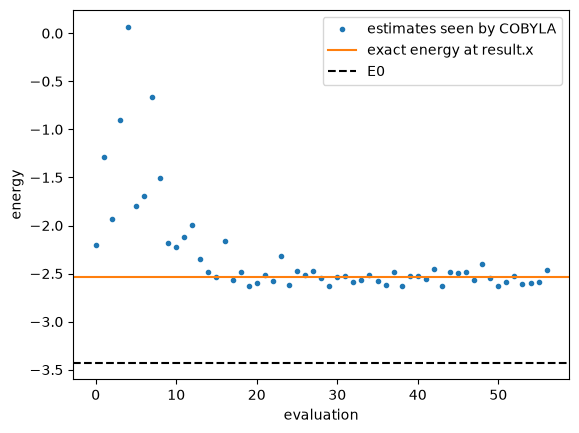

In [11]:
plt.plot(history, ".", label="estimates seen by COBYLA")
plt.axhline(energy_exact(result.x), color="tab:orange", label="exact energy at result.x")
plt.axhline(E0, color="black", linestyle="--", label="E0")
plt.xlabel("evaluation")
plt.ylabel("energy")
plt.legend()
plt.show()

**Think.** With exact energies, COBYLA needed about 250 evaluations and ended 0.003 above $E_0$.
With shots, it stopped after about 60, much further from $E_0$, although its message is the same.
And `result.fun` is lower than the exact energy at `result.x`. Why? Exercises 2 and 3 come back to
these points.

<!-- BEGIN SOLUTION -->
**Solution.** The message says that the *trust region*, the size of the steps that COBYLA tries,
has shrunk to its lower bound, which COBYLA takes as convergence. With shots, the energy
differences between nearby angles soon become smaller than the standard error of an estimate
(about 0.05 here), so steps that should help look worse; COBYLA then shrinks its steps too fast,
and stops early. `result.fun` is the lowest of the estimates in `history`, and the lowest of about
60 estimates is usually one that fluctuated downwards, so it is biased low (notes, section ["The
variational quantum eigensolver"](https://stefanopolla.github.io/course-testing/L4-ground-states.html#sec-vqe-loop)). To know the energy of the state found, we estimate it again at
`result.x`, with fresh shots.
<!-- END SOLUTION -->

### Summary: from Lecture 4 to code

| Lecture 4 | Qiskit and scipy |
| --- | --- |
| a circuit with parameters $\theta$ | `theta = ParameterVector("theta", m)`, then `circuit.rx(theta[0], q)`, ... |
| the circuit at given angles | `circuit.assign_parameters(angles)` |
| minimise $E(\theta)$ from $\theta_0$ | `result = minimize(f, x0, method="COBYLA")` |
| further arguments of $f$ | `minimize(f, x0, args=(shots, history), method="COBYLA")` |
| at most $m$ evaluations | `minimize(..., options={"maxiter": m})` |
| what the optimiser found | `result.x`, `result.fun`, `result.nfev`, `result.message` |

## Part B: exercises

Exercises 1, 2 and 3 are the core of this tutorial; 4 and 5 go further. Use the functions from
Part A. Every run with shots is random, so your numbers will differ a little from those quoted in
the text.

### Exercise 1 (core): the adiabatic circuit, without an optimiser

Before we optimise any angles, we run the adiabatic circuit itself (notes, section ["Adiabatic
circuits"](https://stefanopolla.github.io/course-testing/L4-ground-states.html#sec-adiabatic-circuits)): Trotter steps of length $\delta$ along the path
$H(s) = -sJ\sum_i Z_iZ_{i+1} - h\sum_i X_i$, from $|{+}\cdots{+}\rangle$, up to the total time
$T$. With `steps = round(T / delta)`, this is `hva_ansatz(n, steps)` with the angles
`schedule(steps, T)` of Part A.

**(a) (code)** For the step lengths $\delta = 0.25$, $0.5$ and $1$, and the total times
$T = 1, 2, \dots, 16$, compute the fidelity $|\langle E_0|\psi(T)\rangle|^2$ of the final state
with the ground state, and its exact energy minus $E_0$. `state_fidelity(state, ground_state)` is
the fidelity of two `Statevector`s, and `state.expectation_value(hamiltonian).real` the energy, as
in `energy_exact`. The plotting code is given: `plt.subplots(1, 2)` makes two plots side by side,
`ax_fidelity` and `ax_energy`.

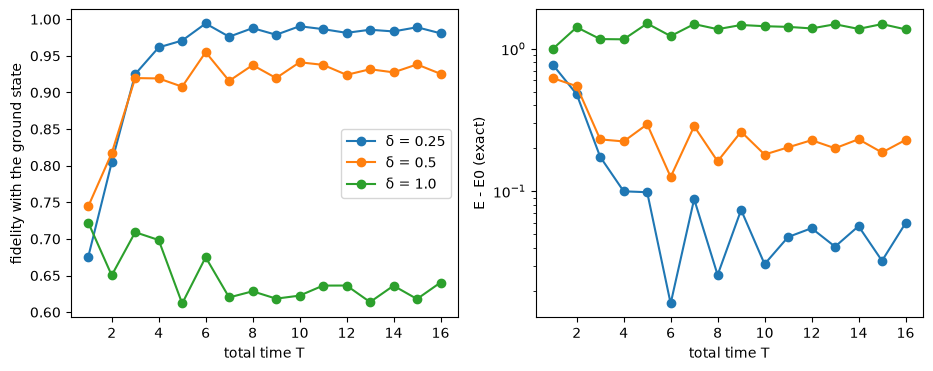

In [12]:
from qiskit.quantum_info import state_fidelity

_, vectors = np.linalg.eigh(hamiltonian.to_matrix())
ground_state = Statevector(vectors[:, 0])         # the eigenvector of the lowest eigenvalue
total_times = np.arange(1, 17)                    # T = 1, 2, ..., 16

fig, (ax_fidelity, ax_energy) = plt.subplots(1, 2, figsize=(11, 4))
for delta in [0.25, 0.5, 1.0]:
    fidelities = []                               # one per total time
    errors = []                                   # the exact energy minus E0, one per total time
    for T in total_times:
        steps = round(T / delta)
        # the adiabatic circuit with these steps up to time T; append its fidelity and E - E0
        # BEGIN SOLUTION
        state = Statevector(hva_ansatz(n, steps).assign_parameters(schedule(steps, T)))
        fidelities.append(state_fidelity(state, ground_state))
        errors.append(state.expectation_value(hamiltonian).real - E0)
        # END SOLUTION
    ax_fidelity.plot(total_times, fidelities, "o-", label="δ = " + str(delta))
    ax_energy.semilogy(total_times, errors, "o-", label="δ = " + str(delta))
ax_fidelity.set_xlabel("total time T")
ax_fidelity.set_ylabel("fidelity with the ground state")
ax_energy.set_xlabel("total time T")
ax_energy.set_ylabel("E - E0 (exact)")
ax_fidelity.legend()
plt.show()

**(b) (paper)** (1) For each $\delta$, the fidelity rises with $T$ and then levels off, lower for
larger $\delta$; with $\delta = 1$, a longer evolution does not help at all. Why? (Hint: notes,
section ["Adiabatic circuits"](https://stefanopolla.github.io/course-testing/L4-ground-states.html#sec-adiabatic-circuits): which Hamiltonian does a slow Trotter circuit follow?) (2) For
$\delta = 0.25$, how many Trotter steps does the first circuit with a fidelity above 0.99 have,
and how many CZs, with 2 CZs per bond gate? With an error of 0.5% per CZ, what is the probability
that it runs without an error? Compare with the 3 layers of `ansatz`, whose optimised angles of A2
reach a fidelity of 0.999.

<!-- BEGIN SOLUTION -->
**Solution.** (1) Two errors compete. If $T$ is short, the evolution is too fast for the gap,
and part of the state leaks into excited states (notes, section ["Adiabatic state preparation"](https://stefanopolla.github.io/course-testing/L4-ground-states.html#sec-adiabatic));
this error falls as $T$ grows. The Trotter error does not: each step evolves the state exactly,
but under the Floquet Hamiltonian $H_F$, which differs from $H(s)$ by terms that grow with
$\delta$ (notes, section ["Adiabatic circuits"](https://stefanopolla.github.io/course-testing/L4-ground-states.html#sec-adiabatic-circuits)). A slow circuit therefore prepares the ground state
of $H_F$, not of $H$, and the fidelity levels off at the overlap of the two: about 0.98 for
$\delta = 0.25$, 0.93 for $\delta = 0.5$ and 0.63 for $\delta = 1$, up to small oscillations. With
$\delta = 1$, this level is no higher than what the shortest circuits already reach, so a longer
evolution does not help.

(2) With $\delta = 0.25$, the fidelity first exceeds 0.99 at $T = 6$ (0.994, on a small bump; it
then stays around 0.98 to 0.99): 24 steps, each with 3 bond gates, so 72 bond gates and 144 CZs.
The probability that it runs without an error is $0.995^{144} \approx e^{-0.72} \approx 0.49$. The
3 layers of `ansatz` have 9 bond gates, 18 CZs, and run without an error with probability
$0.995^{18} \approx 0.91$; with optimised angles, their fidelity is 0.999. Optimising the angles
gives a better state with eight times fewer CZs: this is why we turn to the VQE. On the 8 qubits of
the notes, the adiabatic circuit needs 1,120 CZs.
<!-- END SOLUTION -->

**(c) (code, then paper)** On a device, we cannot compute the fidelity, and the energy comes from
shots. Repeat the energy plot with `measure_energy` and 1000 shots per setting, with the standard
errors as error bars: `plt.errorbar(x, y, yerr=...)`. The vertical axis is linear, since an
estimate can fall below $E_0$. Which conclusions of (a) can you still draw from the estimates?

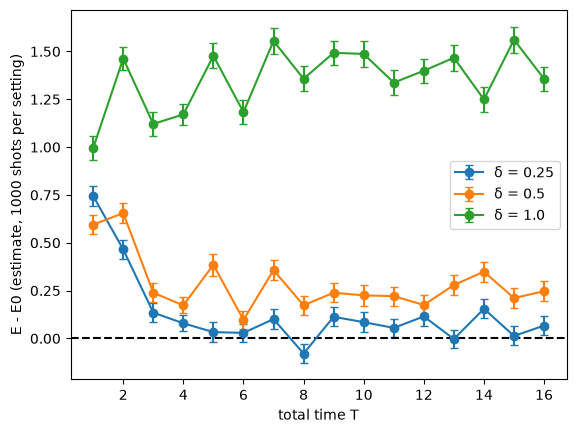

In [13]:
for delta in [0.25, 0.5, 1.0]:
    estimates = []                                # the estimate minus E0, one per total time
    standard_errors = []                          # its standard error, one per total time
    for T in total_times:
        steps = round(T / delta)
        # the estimate of measure_energy for the same circuit; append it minus E0, and its standard error
        # BEGIN SOLUTION
        estimate, error = measure_energy(hva_ansatz(n, steps).assign_parameters(schedule(steps, T)), 1000, J, h)
        estimates.append(estimate - E0)
        standard_errors.append(error)
        # END SOLUTION
    plt.errorbar(total_times, estimates, yerr=standard_errors, fmt="o-", capsize=3, label="δ = " + str(delta))
plt.axhline(0, color="black", linestyle="--")
plt.xlabel("total time T")
plt.ylabel("E - E0 (estimate, 1000 shots per setting)")
plt.legend()
plt.show()

<!-- BEGIN SOLUTION -->
**Solution.** The standard errors are about 0.05 (0.065 for $\delta = 1$). We can still see
that $\delta = 1$ is far worse at every $T$, 1 to 1.6 above $E_0$, and, from $T \approx 3$ on, that
$\delta = 0.5$ ends higher than $\delta = 0.25$: their estimates differ by about 0.15 on average,
three standard errors, although single points can overlap. The levelling off is also visible. We
cannot see how close $\delta = 0.25$ gets to $E_0$ (0.02 to 0.06, less than one standard error),
nor the small oscillations, and some estimates fall below $E_0$, which only shot noise allows. The
fidelity itself we cannot measure at all: a low energy bounds it only if we know the gap (notes,
exercise ["How close is a low energy to the ground state?"](https://stefanopolla.github.io/course-testing/L4-ground-states.html#exr-variational); Exercise 5 uses this).
<!-- END SOLUTION -->

### Exercise 2 (core): gradient descent with the parameter-shift rule, and its cost in shots

Gradient descent steps downhill, $\theta \to \theta - \eta\,\nabla E(\theta)$, with a step size
$\eta$ (notes, section ["Optimising with shots"](https://stefanopolla.github.io/course-testing/L4-ground-states.html#sec-optimisers)). We estimate the gradient with the parameter-shift
rule (notes, section ["The parameter-shift rule"](https://stefanopolla.github.io/course-testing/L4-ground-states.html#sec-parameter-shift)),
$$
\frac{\partial E}{\partial\theta} = \frac{E(\theta + \frac{\pi}{2}) - E(\theta - \frac{\pi}{2})}{2} ,
$$
which holds for an angle that enters a single Pauli rotation. In the HVA, each angle enters
several gates: $\gamma_k$ all $n-1$ bond gates of layer $k$, and $\beta_k$ all its $n$ field
gates. By the product rule, the derivative with respect to a shared angle is the sum of the
derivatives with respect to the angle of each of its gates, so we shift one gate at a time.

For this we need a circuit with its own parameter for each gate. The given function
`hva_ansatz_per_gate` builds the same circuit as `hva_ansatz`, with one parameter per gate, and
also returns the list `angle_of_gate`: gate `g` takes the HVA angle number `angle_of_gate[g]`.
For a numpy array `angles` of HVA angles, `angles[angle_of_gate]` is then the array of the angles
of all the gates, in order. `gate_energy` does for this circuit what `energy_estimate` does for
`ansatz`.

In [14]:
def hva_ansatz_per_gate(n, p):
    """The circuit of hva_ansatz(n, p), with its own parameter for each gate.

    Also returns angle_of_gate: gate g takes the HVA angle angles[angle_of_gate[g]]."""
    phi = ParameterVector("phi", p * (2 * n - 1))
    circuit = QuantumCircuit(n)
    circuit.h(range(n))
    angle_of_gate = []
    g = 0                                                   # the number of gates so far
    bonds = list(range(0, n - 1, 2)) + list(range(1, n - 1, 2))   # (0,1), (2,3), ..., (1,2), ...
    for k in range(p):
        for i in bonds:
            circuit.rzz(phi[g], i, i + 1)
            angle_of_gate.append(2 * k)                     # gamma_k
            g += 1
        for i in range(n):
            circuit.rx(phi[g], i)
            angle_of_gate.append(2 * k + 1)                 # beta_k
            g += 1
    return circuit, angle_of_gate


ansatz_per_gate, angle_of_gate = hva_ansatz_per_gate(n, p)


def gate_energy(gate_angles, shots, history):
    """As energy_estimate, with one angle for each gate of ansatz_per_gate."""
    value, error = measure_energy(ansatz_per_gate.assign_parameters(gate_angles), shots, J, h)
    history.append(value)
    return value


print("angle_of_gate:", angle_of_gate)
print("the angle of each gate at the start:", np.round(start[angle_of_gate], 3))

angle_of_gate: [0, 0, 0, 1, 1, 1, 1, 2, 2, 2, 3, 3, 3, 3, 4, 4, 4, 5, 5, 5, 5]
the angle of each gate at the start: [-0.333 -0.333 -0.333 -1.    -1.    -1.    -1.    -1.    -1.    -1.
 -1.    -1.    -1.    -1.    -1.667 -1.667 -1.667 -1.    -1.    -1.
 -1.   ]


**(a) (paper)** For our circuit ($n = 4$, $p = 3$), how many gates does one gradient shift, and
how many energy estimates and shots does it cost with 1000 shots per setting? Why can we not
shift $\gamma_k$ by $\pi/2$ in all its gates at once? (Hint: the bond gates of layer $k$ together
are $e^{-i\gamma_k P/2}$ with $P = \sum_i Z_iZ_{i+1}$. Which property of $P$ does the derivation
of the rule use?)

<!-- BEGIN SOLUTION -->
**Solution.** Each layer has 3 bond gates and 4 field gates, so the circuit has 21 parametrised
gates. One gradient costs two estimates per gate, 42 estimates, and so
$42 \times 2 \times 1000 = 84\,000$ shots; one COBYLA evaluation costs a single estimate.

The derivation uses $P^2 = I$, which makes the energy along one angle a single sinusoid. For
$P = Z_0Z_1 + Z_1Z_2 + Z_2Z_3$, $P^2 \ne I$: its eigenvalues are $-3, -1, 1, 3$, so the energy as a
function of $\gamma_k$ also contains $\cos 2\gamma_k$ and $\cos 3\gamma_k$ (and the sines), and the
shift by $\pi/2$ of all gates at once does not give its derivative.
<!-- END SOLUTION -->

**(b) (code)** Complete `parameter_shift_gradient`. For each gate `g`, the given lines copy
`gate_angles` into `plus` and `minus` (with `.copy()`, so that changing `plus` does not change
`gate_angles`). Shift the angle of gate `g` by $\pm\pi/2$, and add half the difference of the two
estimates to the derivative of the HVA angle `angle_of_gate[g]`. The cell after it compares your
gradient, with 100 000 shots per setting so that the shot noise is small, with the exact gradient. The exact
gradient is given; it uses finite differences of `energy_exact` with a tiny step, which are
accurate with exact energies (notes, section ["Finite differences"](https://stefanopolla.github.io/course-testing/L4-ground-states.html#sec-finite-differences)).

In [15]:
def parameter_shift_gradient(angles, shots, history):
    """The gradient of the HVA energy at `angles`, by the parameter-shift rule, one gate at a time."""
    gate_angles = angles[angle_of_gate]                     # the angle of each gate
    gradient = np.zeros(len(angles))
    for g in range(len(gate_angles)):
        plus = gate_angles.copy()
        minus = gate_angles.copy()
        # BEGIN SOLUTION
        plus[g] += np.pi / 2
        minus[g] -= np.pi / 2
        derivative = (gate_energy(plus, shots, history) - gate_energy(minus, shots, history)) / 2
        gradient[angle_of_gate[g]] += derivative
        # END SOLUTION
    return gradient

In [16]:
def exact_gradient(angles, step=1e-6):
    """The exact gradient, from finite differences of energy_exact (simulation only)."""
    gradient = np.zeros(len(angles))
    for j in range(len(angles)):
        plus = angles.copy()
        plus[j] += step
        minus = angles.copy()
        minus[j] -= step
        gradient[j] = (energy_exact(plus) - energy_exact(minus)) / (2 * step)
    return gradient


history = []
print("exact:          ", np.round(exact_gradient(start), 3))
print("parameter shift:", np.round(parameter_shift_gradient(start, 100_000, history), 3))
print("estimates used: ", len(history))

exact:           [-0.301 -0.104  0.694  0.535 -1.9   -2.17 ]


parameter shift: [-0.29  -0.107  0.702  0.544 -1.909 -2.175]
estimates used:  42


**(c) (code)** Complete `gradient_descent`. It makes `steps` steps from `angles` and records, after
each step, the exact energy of the new angles: only for our plots, since a device cannot give it.
Then run it from the schedule, with $\eta = 0.1$ and 1000 shots per setting. The plotting code is
given: `plt.semilogy` draws with a logarithmic vertical axis, and `np.array(energies) - E0`
subtracts $E_0$ from every entry.

Finally, change the call to use $\eta = 0.3$, and run the cell again. What happens, and why?
(Hint: along one direction, near the minimum, $E \approx E_{\min} + \frac{c}{2}(\theta - \theta^*)^2$.
By which factor does one step multiply the distance $\theta - \theta^*$?)

shots: 2520000
exact E - E0 after 30 steps: 0.0072


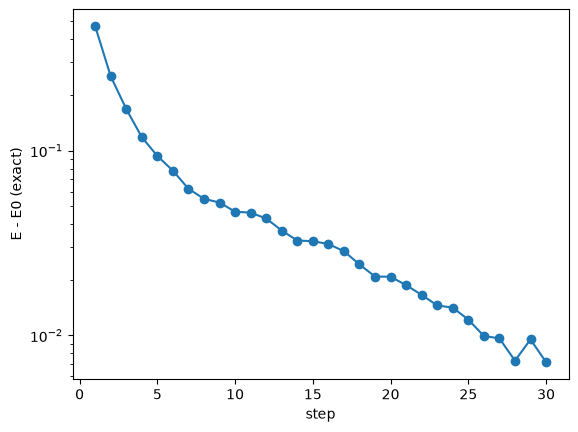

In [17]:
def gradient_descent(angles, eta, steps, shots, history):
    """`steps` steps of gradient descent with step size eta, from `angles`.

    Returns the final angles, and the list of the exact energies after each step (simulation only)."""
    energies = []
    # BEGIN SOLUTION
    for step in range(steps):
        angles = angles - eta * parameter_shift_gradient(angles, shots, history)
        energies.append(energy_exact(angles))
    # END SOLUTION
    return angles, energies


history = []
angles, energies = gradient_descent(start, 0.1, 30, 1000, history)
print("shots:", 2 * 1000 * len(history))
print("exact E - E0 after 30 steps:", round(energies[-1] - E0, 4))

plt.semilogy(range(1, 31), np.array(energies) - E0, "o-")
plt.xlabel("step")
plt.ylabel("E - E0 (exact)")
plt.show()

<!-- BEGIN SOLUTION -->
**Solution.** With $\eta = 0.1$, the error falls to about 0.01 in 30 steps. With $\eta = 0.3$, the
energy jumps up and down and does not settle near $E_0$. For
$E \approx E_{\min} + \frac c2(\theta - \theta^*)^2$, the gradient is $c(\theta - \theta^*)$, so one
step multiplies the distance from the minimum by $1 - \eta c$. The distance shrinks only if
$|1 - \eta c| < 1$, that is $\eta < 2/c$; otherwise every step overshoots, further each time. The
energy curves differently in different directions, and the most curved one sets the limit: here
its second derivative at the minimum is about 12.6, so $\eta$ must be below about 0.16. With
$\eta = 0.1$ the steps converge; with 0.3 they do not.
<!-- END SOLUTION -->

**What an optimisation costs in shots.** In the notes, the final accuracy of an optimisation is limited by the number of shots. Here we
measure the *total* number of shots that an optimisation spends, for COBYLA and for gradient
descent, with $N = 100$, 1000 and 10 000 shots per setting for every estimate. As the measure of
accuracy we use the exact energy of the angles found, minus $E_0$: a device cannot give it, but in
simulation it tells us how good the state really is.

**(d) (code)** Complete the loop. For each $N$, `cobyla_shots` is the number of shots of the COBYLA
run, and `cobyla_error` the exact energy at its final angles minus $E_0$; `gd_shots` and `gd_errors`
are arrays with one entry per step of gradient descent: the shots used up to that step, and the
exact energy after it minus $E_0$. Every step costs the same number of shots, and
`np.arange(1, steps + 1)` is the array $1, 2, \dots,$ `steps`. The plotting code is given:
`plt.loglog` draws with both axes logarithmic, and each $N$ gets its own colour, a line for
gradient descent and a square for COBYLA. (About 10 seconds.)

N = 100   COBYLA: 11600 shots, E - E0 = 0.624   gradient descent: 252000 shots, E - E0 = 0.0219


N = 1000   COBYLA: 128000 shots, E - E0 = 0.26   gradient descent: 2520000 shots, E - E0 = 0.0104


N = 10000   COBYLA: 1220000 shots, E - E0 = 0.212   gradient descent: 25200000 shots, E - E0 = 0.0069


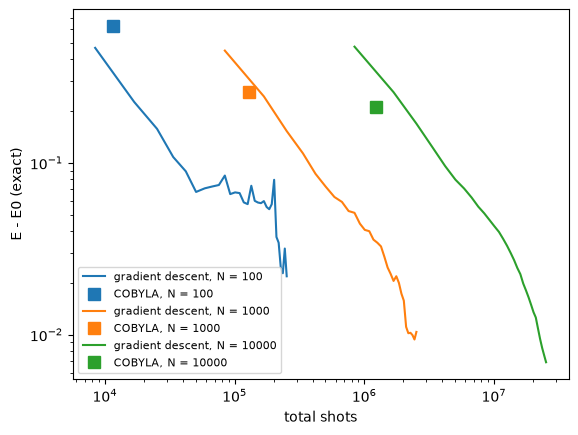

In [18]:
steps = 30
for N, colour in zip([100, 1000, 10_000], ["tab:blue", "tab:orange", "tab:green"]):
    cobyla_history = []
    result_N = minimize(energy_estimate, start, args=(N, cobyla_history), method="COBYLA")
    gd_history = []
    angles_N, energies_N = gradient_descent(start, 0.1, steps, N, gd_history)
    # cobyla_shots, cobyla_error: one number each; gd_shots, gd_errors: arrays, one entry per step
    # BEGIN SOLUTION
    cobyla_shots = 2 * N * len(cobyla_history)
    cobyla_error = energy_exact(result_N.x) - E0
    shots_per_step = 2 * N * len(gd_history) / steps
    gd_shots = shots_per_step * np.arange(1, steps + 1)
    gd_errors = np.array(energies_N) - E0
    # END SOLUTION
    print("N =", N, "  COBYLA:", cobyla_shots, "shots, E - E0 =", round(cobyla_error, 3),
          "  gradient descent:", int(gd_shots[-1]), "shots, E - E0 =", round(gd_errors[-1], 4))
    plt.loglog(gd_shots, gd_errors, "-", color=colour, label="gradient descent, N = " + str(N))
    plt.loglog(cobyla_shots, cobyla_error, "s", color=colour, markersize=9, label="COBYLA, N = " + str(N))

plt.xlabel("total shots")
plt.ylabel("E - E0 (exact)")
plt.legend(fontsize=8)
plt.show()

**(e) (paper)** From the plot and the printout: (1) How many shots does each optimiser need to get
below $E - E_0 = 0.05$, if it gets there at all? (2) Why does COBYLA stop long before reaching
$E_0$, even with $N = 10\,000$, while gradient descent keeps improving? (3) After 30 steps,
gradient descent ends at about the same error with $N = 1000$ and with $N = 10\,000$. What limits
it there, and what limits it with $N = 100$?

<!-- BEGIN SOLUTION -->
**Solution.** (1) Gradient descent with $N = 100$ gets below 0.05 after 10 to 20 steps, that is
with 1 to $2 \times 10^5$ shots, and ends between 0.01 and 0.05. With $N = 1000$, it needs about
10 steps, as many as with exact energies, but ten times more shots per step (about $9 \times 10^5$
in all), and with $N = 10\,000$ a hundred times more. COBYLA does not get below 0.05 with any $N$
(not once in 60 runs): it stops after 50 to 80 evaluations, typically about 1 above $E_0$ with
$N = 100$, no better than the start, 0.25 with $N = 1000$ and 0.1 with $N = 10\,000$, with a large
spread from run to run.

(2) COBYLA compares single estimates. Once the energy differences of the angles it tries are
smaller than the standard error of an estimate (about 0.17, 0.05 and 0.017 for the three $N$), it
cannot tell a better step from a worse one; it shrinks its steps and stops (Part A). Ten times more
shots lower the standard error only by about 3, so it stops later, but still far from $E_0$.
Gradient descent does not compare estimates: it moves along the estimated gradient, whose noise is
random from step to step and largely averages out over many steps, while the true gradient keeps
pointing downhill.

(3) With $N = 1000$ and $10\,000$, the gradient is accurate enough for gradient descent to follow
the path it takes with exact energies, which after 30 steps is still about 0.007 above $E_0$ (it
reaches the limit of the ansatz, 0.003, after about 50 steps): the number of steps limits it.
With $N = 100$, the shot noise does: near the minimum, the true gradient becomes as small as the
noise of the estimated one, and the angles jitter around the minimum, here 0.01 to 0.05 above
$E_0$.

What counts is the total number of shots for a given accuracy. A gradient costs 42 estimates and a
COBYLA evaluation one, and still gradient descent with few shots per estimate is the cheapest way to
get close to $E_0$ here.
<!-- END SOLUTION -->

### Exercise 3 (core): find the mistakes

The cell below runs a VQE with shots, with both optimisers, and the report after it draws
conclusions from the output. The code runs without errors, but it contains **three conceptual
mistakes**, which make the report wrong: one in the COBYLA part, one in the gradient-descent part,
and one in the comparison of the two.

**Your task.** (a) Find each mistake, and explain in one or two sentences why it is wrong. (b) Fix
the code (in the empty cell after the report, starting from a copy of this one), run it, and
correct the report.

The mistakes are about what the numbers mean, not about Python. For each claim of the report, ask
how the number behind it was obtained, and what it cost. Change and re-run parts of the code to
test your guesses. The notes, sections ["The variational quantum eigensolver"](https://stefanopolla.github.io/course-testing/L4-ground-states.html#sec-vqe-loop) and ["Gradients from
shots"](https://stefanopolla.github.io/course-testing/L4-ground-states.html#sec-gradients), and Exercise 2 will help.

In [19]:
# A VQE with shots, and its report. This cell contains three conceptual mistakes.
shots = 1000
eta = 0.1                 # the step size of gradient descent
iterations = 20

# COBYLA
cobyla_history = []
cobyla_result = minimize(energy_estimate, start, args=(shots, cobyla_history), method="COBYLA")
cobyla_energy = cobyla_result.fun


# Gradient descent, with the gradient from finite differences: two estimates per angle, so 12 in
# all, instead of 42 for the parameter-shift rule. A small step makes the derivatives accurate.
def finite_difference_gradient(angles, shots, history, step=0.01):
    gradient = np.zeros(len(angles))
    for j in range(len(angles)):
        plus = angles.copy()
        plus[j] += step
        minus = angles.copy()
        minus[j] -= step
        gradient[j] = (energy_estimate(plus, shots, history) - energy_estimate(minus, shots, history)) / (2 * step)
    return gradient


gd_history = []
gd_angles = start.copy()
for iteration in range(iterations):
    gd_angles = gd_angles - eta * finite_difference_gradient(gd_angles, shots, gd_history)
gd_energy, gd_error = measure_energy(ansatz.assign_parameters(gd_angles), shots, J, h)

print("start:            E - E0 =", round(energy_exact(start) - E0, 3))
print("COBYLA:           E - E0 =", round(cobyla_energy - E0, 3), "  iterations:", cobyla_result.nfev)
print("gradient descent: E - E0 =", round(gd_energy - E0, 3), "±", round(gd_error, 3), "  iterations:", iterations)

start:            E - E0 = 1.168
COBYLA:           E - E0 = 0.205   iterations: 69
gradient descent: E - E0 = 1.237 ± 0.06   iterations: 20


**Report.**

1. *COBYLA.* COBYLA stopped when its trust region reached its lower bound. Its energy, printed
   above, is the energy of the state it found, up to the standard error of one estimate: about 0.05
   with 1000 shots per setting.
2. *Gradient descent.* Gradient descent did not converge: after 20 iterations, its energy is far
   above that of COBYLA, and often above the start. The step size `eta` = 0.1 is too large, so
   every step overshoots the minimum; a smaller `eta`, with more iterations, will fix this.
3. *Comparison.* Gradient descent needs fewer iterations than COBYLA (`iterations` = 20, against the
   number printed above), so once its step size is fixed, it is also the cheaper optimiser of the two.

<!-- BEGIN SOLUTION -->
**Solution.** (a) The three mistakes:

1. *COBYLA:* `cobyla_result.fun` is the lowest of all the estimates COBYLA saw, so it is biased
   low (Part A, Think): it is not an estimate of the energy of the final state. The fix is a fresh
   estimate at `cobyla_result.x`, which is what we report on a device, with its standard error. It
   is higher, typically by about 0.1, and so is the error of the VQE.
2. *Gradient descent:* the finite-difference step 0.01 is far too small for estimates with shots.
   The difference of two estimates has a standard error of about $0.05\sqrt2 \approx 0.07$, and
   dividing by $2 \times 0.01$ turns it into about 3.5 in every derivative, larger than the
   derivatives themselves (between 0.1 and 2 at the start): the gradient is mostly shot noise
   (estimate it twice at the same angles, and the two vectors have little in common), and gradient
   descent walks at random. A smaller `eta` only makes this random walk slower; `eta` = 0.1 works
   well with a good gradient (Exercise 2(c)). The fix is a step of about 0.5 (notes, section ["Finite
   differences"](https://stefanopolla.github.io/course-testing/L4-ground-states.html#sec-finite-differences)), or the parameter-shift rule of Exercise 2.
3. *Comparison:* an iteration of gradient descent costs 12 estimates, one of COBYLA a single
   estimate. Compared in shots, the 20 steps of gradient descent cost 240 estimates (480 000
   shots), three to five times the 50 to 80 estimates of COBYLA (100 000 to 160 000 shots).

(b) After the fixes (cell below), a corrected report: COBYLA used 100 000 to 160 000 shots and,
according to a fresh estimate, ended typically 0.1 to 0.5 above $E_0$ (in simulation, the exact
energy agrees); the lowest estimate it saw was about 0.1 lower. Gradient descent used 480 000
shots, three to five times more, and ended about 0.02 above $E_0$ (exact), too close for a fresh
estimate with 1000 shots to resolve. It costs more shots, but it is the only one of the two that
gets close to the ground state (Exercise 2(e)).

With a step of 0.5, finite differences need 12 estimates per gradient against 42 for the
parameter-shift rule, and work about as well here: for angles shared by many gates, they are the
cheaper choice, provided the step is large enough.
<!-- END SOLUTION -->

In [20]:
# Your corrected version of the cell above
# BEGIN SOLUTION
# Fix 1: estimate the energy at COBYLA's final angles again, with fresh shots
cobyla_energy, cobyla_error = measure_energy(ansatz.assign_parameters(cobyla_result.x), shots, J, h)

# Fix 2: a finite-difference step of 0.5 (or parameter_shift_gradient of Exercise 2)
gd_history = []
gd_angles = start.copy()
for iteration in range(iterations):
    gd_angles = gd_angles - eta * finite_difference_gradient(gd_angles, shots, gd_history, step=0.5)
gd_energy, gd_error = measure_energy(ansatz.assign_parameters(gd_angles), shots, J, h)

# Fix 3: compare the shots, not the iterations
print("COBYLA:           E - E0 =", round(cobyla_energy - E0, 3), "±", round(cobyla_error, 3),
      " (lowest estimate seen:", round(cobyla_result.fun - E0, 3),
      ", exact:", round(energy_exact(cobyla_result.x) - E0, 3), ")  shots:", 2 * shots * len(cobyla_history))
print("gradient descent: E - E0 =", round(gd_energy - E0, 3), "±", round(gd_error, 3),
      " (exact:", round(energy_exact(gd_angles) - E0, 3), ")  shots:", 2 * shots * len(gd_history))
# END SOLUTION

COBYLA:           E - E0 = 0.393 ± 0.06  (lowest estimate seen: 0.205 , exact: 0.353 )  shots: 138000
gradient descent: E - E0 = -0.031 ± 0.051  (exact: 0.02 )  shots: 480000


### Exercise 4 (further): noise, and how many layers

Gate noise biases the energy. Depolarising noise pulls every expectation value towards zero
(Tutorial 2), so the energy rises towards that of the maximally mixed state,
$\mathrm{Tr}[H]/2^n = 0$. More layers make a better ansatz, but they add gates, and so noise: the
same trade-off as for the number of Trotter steps in Tutorial 3, Exercise 2.

We use the noise model and the density-matrix simulation of Tutorials 2 and 3 (copied below), with
the values of today's devices, $p = 0.1\%$ after every `r` gate and $0.5\%$ after every CZ. We
compute the noisy energy exactly, without shots, to see the bias alone: `noisy_density_matrix`
returns a density matrix $\rho$, and `rho.expectation_value(hamiltonian).real` is
$\mathrm{Tr}[\rho H]$. `circuit_energy` is `energy_exact` for any circuit, given as its second
argument.

In [21]:
from qiskit_aer.noise import NoiseModel, depolarizing_error


def native_noise_model(p1, p2):
    """Depolarising errors after every r gate (p1) and every cz gate (p2), as in Tutorial 2, A2."""
    noise_model = NoiseModel()
    noise_model.add_all_qubit_quantum_error(depolarizing_error(p1, 1), ["r"])
    noise_model.add_all_qubit_quantum_error(depolarizing_error(p2, 2), ["cz"])
    return noise_model


def noisy_density_matrix(circuit, noise_model):
    """Exact final density matrix of `circuit` (native gates, no measurements) under `noise_model`.

    From Tutorial 2, A3."""
    circuit = circuit.copy()
    circuit.save_density_matrix()
    density_simulator = AerSimulator(method="density_matrix", noise_model=noise_model)
    return density_simulator.run(circuit).result().data()["density_matrix"]


def circuit_energy(angles, circuit):
    """The exact energy of the state that `circuit` prepares with these angles (simulation only)."""
    return Statevector(circuit.assign_parameters(angles)).expectation_value(hamiltonian).real

**(a) (code, then paper)** Compile `ansatz` with the angles found in A2, `result_exact.x`, to `r`
and `cz` (with `optimization_level=1`, as in Tutorial 3), and print its gate counts. Then compute
its noisy energy.

From the gate counts, estimate as in Tutorial 2 the probability $f$ that the circuit runs without
an error, with the error probabilities $3p/4$ for an `r` gate and $15p/16$ for a CZ. If every error
turned the state into the maximally mixed state, the noisy energy would be $fE$: what bias
$E_{\text{noisy}} - E$ does this predict? Compare with the simulation.

In [22]:
noise_model = native_noise_model(0.001, 0.005)
# native: the circuit with the angles result_exact.x, compiled to r and cz; print its gate counts.
# noisy_energy: Tr[rho H] for its noisy density matrix
# BEGIN SOLUTION
native = transpile(ansatz.assign_parameters(result_exact.x), basis_gates=["r", "cz"], optimization_level=1)
print(native.count_ops())
rho = noisy_density_matrix(native, noise_model)
noisy_energy = rho.expectation_value(hamiltonian).real
# END SOLUTION
print("without noise: E - E0 =", round(result_exact.fun - E0, 4))
print("with noise:    E - E0 =", round(noisy_energy - E0, 4))

OrderedDict({'r': 58, 'cz': 18})
without noise: E - E0 = 0.0032
with noise:    E - E0 = 0.277


<!-- BEGIN SOLUTION -->
**Solution.** The compiled circuit has 58 `r` gates and 18 CZs, so
$f \approx (1 - 0.00075)^{58}(1 - 0.0047)^{18} \approx 0.957 \times 0.919 \approx 0.88$, and the
predicted bias is $(1 - f)\,|E| \approx 0.12 \times 3.42 \approx 0.41$. The simulation gives
about 0.27, less than predicted: not every error changes the energy. Each term of $H$ acts on one
or two qubits, and only the errors in its light cone can change it (Tutorial 2, Exercise 4); some
Pauli errors also leave a term unchanged. The bias is still about 80 times the error of the ansatz
(0.003), and five times the standard error of an estimate with 1000 shots: with noise, it is the
largest error of the VQE.
<!-- END SOLUTION -->

**(b) (code, then paper)** For $p = 1, \dots, 5$ layers, minimise the exact energy with COBYLA,
starting from the schedule with steps of length 1, `schedule(layers, layers)`, and record the
optimised angles and the remaining error. `minimize` passes the circuit to `circuit_energy` with
`args=(circuit,)`: the comma makes `(circuit,)` a tuple with one element. Then complete
`noisy_errors`, which compiles each optimised circuit and returns its noisy energy minus $E_0$.
The plotting code is given; `plt.ylim(1e-3, 3)` sets the range of the vertical axis, so errors
below $10^{-3}$ are off the plot. Which number of layers gives the lowest noisy energy, with today's
noise? And with the noise of Tutorial 2, five times stronger, or with noise five times weaker than
today's?

without noise, E - E0: [0.4236 0.1574 0.0032 0.0029 0.    ]
today's noise, E - E0: [0.501 0.328 0.277 0.343 0.457]


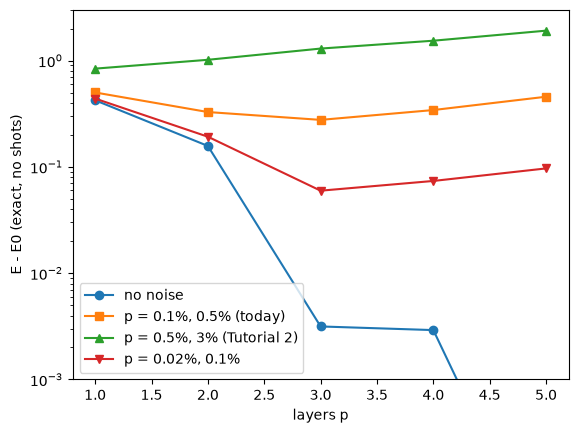

In [23]:
layer_numbers = [1, 2, 3, 4, 5]
optimised = []        # the optimised angles, one array per number of layers
ideal_errors = []     # the exact energy without noise minus E0, one per number of layers
for layers in layer_numbers:
    circuit = hva_ansatz(n, layers)
    # BEGIN SOLUTION
    result_layers = minimize(circuit_energy, schedule(layers, layers), args=(circuit,), method="COBYLA")
    optimised.append(result_layers.x)
    ideal_errors.append(result_layers.fun - E0)
    # END SOLUTION
print("without noise, E - E0:", np.round(ideal_errors, 4))


def noisy_errors(noise_model):
    """The noisy energy minus E0 at the optimised angles, one per number of layers."""
    errors = []
    # For each number of layers and its optimised angles, zip(layer_numbers, optimised): compile the
    # circuit to r and cz, and append Tr[rho H] - E0
    # BEGIN SOLUTION
    for layers, angles in zip(layer_numbers, optimised):
        circuit = hva_ansatz(n, layers).assign_parameters(angles)
        native = transpile(circuit, basis_gates=["r", "cz"], optimization_level=1)
        rho = noisy_density_matrix(native, noise_model)
        errors.append(rho.expectation_value(hamiltonian).real - E0)
    # END SOLUTION
    return errors


today = noisy_errors(native_noise_model(0.001, 0.005))
print("today's noise, E - E0:", np.round(today, 3))
plt.semilogy(layer_numbers, ideal_errors, "o-", label="no noise")
plt.semilogy(layer_numbers, today, "s-", label="p = 0.1%, 0.5% (today)")
plt.semilogy(layer_numbers, noisy_errors(native_noise_model(0.005, 0.03)), "^-", label="p = 0.5%, 3% (Tutorial 2)")
plt.semilogy(layer_numbers, noisy_errors(native_noise_model(0.0002, 0.001)), "v-", label="p = 0.02%, 0.1%")
plt.ylim(1e-3, 3)
plt.xlabel("layers p")
plt.ylabel("E - E0 (exact, no shots)")
plt.legend()
plt.show()

<!-- BEGIN SOLUTION -->
**Solution.** Without noise, the error falls from 0.42 (1 layer) to 0.16 (2) and 0.003 (3), and
then hardly changes: 3 layers are enough for this chain. With today's noise, the noisy error is
about 0.50, 0.33, 0.28, 0.34 and 0.46 for 1 to 5 layers, so 3 layers are best, and almost all of
their error is noise. With the noise of Tutorial 2, 1 layer is best, with an error of about 0.8:
every circuit is far from the ground state. With five times less noise than today, 3 layers are
again best, at about 0.06.

As with the Trotter steps of Tutorial 3, the best depth balances the error of the circuit itself
against the noise, which grows with every layer (by about 0.06 to 0.1 per layer with today's
noise). Here the ideal error drops steeply up to 3 layers and then stops falling, so the best
depth is 3 unless the noise is strong. Optimising the noisy energy directly, as a VQE on a device
does, would not change this much: depolarising noise shrinks the energy by nearly the same factor
for all angles, so the angles cannot avoid it.
<!-- END SOLUTION -->

### Exercise 5 (further): a hardware-efficient ansatz, and barren plateaus

The hardware-efficient ansatz of the notes (section ["Choosing an ansatz"](https://stefanopolla.github.io/course-testing/L4-ground-states.html#sec-ansatz)) applies, in each layer,
a PRX gate with its own two angles to every qubit, then CZ gates on the bonds
$(0,1), (2,3), \dots$, and then on $(1,2), (3,4), \dots$. In Qiskit, PRX$(\theta, \varphi)$ is
`circuit.r(theta, phi, qubit)` (Tutorial 2).

**(a) (code, then paper)** Complete `hardware_efficient_ansatz`. Then minimise its exact energy with
COBYLA for 2 layers (16 angles), starting from small random angles,
`np.random.uniform(-0.1, 0.1, 16)` (angles close to zero start from a simple state, notes section
["Choosing an ansatz"](https://stefanopolla.github.io/course-testing/L4-ground-states.html#sec-ansatz)), with at most 1000 evaluations. The next cell compares the result with the
HVA of A2: the remaining error, the evaluations, and the fidelity with the ground state, whose
vector `np.linalg.eigh` returns as the first column of its second output.

The hardware-efficient ansatz ends close to $E_0 + 0.05$. The lowest state of the other parity
(notes, section ["Adiabatic state preparation"](https://stefanopolla.github.io/course-testing/L4-ground-states.html#sec-adiabatic)) lies $E_1 - E_0 = 0.095$ above the ground state.
Using the notes' exercise ["How close is a low energy to the ground state?"](https://stefanopolla.github.io/course-testing/L4-ground-states.html#exr-variational), explain the fidelity
you find. Why does the HVA not have this problem?

In [24]:
def hardware_efficient_ansatz(n, layers):
    """`layers` layers of PRX on every qubit (two angles each), then CZ on the bonds in two brick layers."""
    theta = ParameterVector("theta", 2 * n * layers)
    circuit = QuantumCircuit(n)
    j = 0                                        # the number of angles used so far
    # BEGIN SOLUTION
    for _ in range(layers):
        for i in range(n):
            circuit.r(theta[j], theta[j + 1], i)
            j += 2
        for i in range(0, n - 1, 2):
            circuit.cz(i, i + 1)
        for i in range(1, n - 1, 2):
            circuit.cz(i, i + 1)
    # END SOLUTION
    return circuit


hea = hardware_efficient_ansatz(n, 2)
print(hea.draw())

     ┌──────────────────────┐    ┌──────────────────────┐ »
q_0: ┤ R(theta[0],theta[1]) ├─■──┤ R(theta[8],theta[9]) ├─»
     ├──────────────────────┤ │  └──────────────────────┘ »
q_1: ┤ R(theta[2],theta[3]) ├─■─────────────■─────────────»
     ├──────────────────────┤               │             »
q_2: ┤ R(theta[4],theta[5]) ├─■─────────────■─────────────»
     ├──────────────────────┤ │ ┌────────────────────────┐»
q_3: ┤ R(theta[6],theta[7]) ├─■─┤ R(theta[14],theta[15]) ├»
     └──────────────────────┘   └────────────────────────┘»
«                                     
«q_0: ───────────────────────────■────
«     ┌────────────────────────┐ │    
«q_1: ┤ R(theta[10],theta[11]) ├─■──■─
«     ├────────────────────────┤    │ 
«q_2: ┤ R(theta[12],theta[13]) ├─■──■─
«     └────────────────────────┘ │    
«q_3: ───────────────────────────■────
«                                     


In [25]:
from qiskit.quantum_info import state_fidelity

energies, vectors = np.linalg.eigh(hamiltonian.to_matrix())
ground_state = Statevector(vectors[:, 0])
print("E1 - E0 =", round(energies[1] - E0, 4))

# result_hea: minimise circuit_energy for `hea` from small random angles, with options={"maxiter": 1000}
# BEGIN SOLUTION
result_hea = minimize(circuit_energy, np.random.uniform(-0.1, 0.1, hea.num_parameters), args=(hea,),
                      method="COBYLA", options={"maxiter": 1000})
# END SOLUTION

for name, circuit, res in [("HVA", ansatz, result_exact), ("hardware-efficient", hea, result_hea)]:
    state = Statevector(circuit.assign_parameters(res.x))
    print(name, ":  E - E0 =", round(res.fun - E0, 4), "  evaluations:", res.nfev,
          "  fidelity:", round(state_fidelity(state, ground_state), 3))

E1 - E0 = 0.0948


HVA :  E - E0 = 0.0032   evaluations: 249   fidelity: 0.999
hardware-efficient :  E - E0 = 0.0543   evaluations: 1000   fidelity: 0.515


<!-- BEGIN SOLUTION -->
**Solution.** The hardware-efficient ansatz uses all 1000 evaluations and ends about 0.05 to 0.07
above $E_0$, with a fidelity of about 0.5; the HVA, with 6 angles instead of 16, ends 0.003 above
$E_0$ after about 250 evaluations, with a fidelity of 0.999. In the notes' exercise,
$F \ge 1 - (E - E_0)/\Delta$; with $\Delta = E_1 - E_0 = 0.095$ and $E - E_0 \approx 0.047$, this
only guarantees $F \ge 0.5$. The state found is close to an equal superposition of the ground
state (parity $+1$) and the lowest state of parity $-1$, whose energy is halfway between the two.
The ground state has most of its weight (80%) on $(|0000\rangle + |1111\rangle)/\sqrt2$, and the
other state on $(|0000\rangle - |1111\rangle)/\sqrt2$, so their equal superposition is mostly
$|0000\rangle$ (85%): from its start near $|0000\rangle$, the hardware-efficient ansatz reaches it
much more easily than the entangled ground state, which lies only 0.047 lower. The HVA starts from $|{+}{+}{+}{+}\rangle$, of parity $+1$, and all its gates conserve
the parity, so it never mixes in the state of parity $-1$: for the HVA, the relevant gap is the one
to the next state of parity $+1$, 1.7 above $E_0$.
<!-- END SOLUTION -->

**(b) (code, then paper)** Barren plateaus. Complete `slope_spread`: for `samples` random choices of
all the angles (uniform between 0 and $2\pi$), compute the derivative of the energy with respect to
the first parameter, with the parameter-shift rule and exact energies, and return the standard
deviation of these derivatives (`np.std`). In both circuits below, the first parameter enters a
single gate: the $\theta$ of the first PRX of the hardware-efficient ansatz, and the angle of the
first bond gate of `hva_ansatz_per_gate`. This function is defined in the first code cell
of Exercise 2: run that cell first, if you have not done Exercise 2. The cell then computes the spread for chains of 2 to 10
qubits, with $4n$ layers, as in the figure of the notes (the figure uses the shared first angle of
the HVA instead). (About 10 seconds.)

By which factor does the spread of the hardware-efficient ansatz fall for every two qubits added,
from 6 qubits on? At that rate, how many more qubits make the typical slope 100 times smaller than
at 10 qubits, and how many more shots would it take to tell its sign?

hardware-efficient: [0.476 0.389 0.252 0.151 0.076]
HVA:                [0.825 0.588 0.454 0.393 0.378]


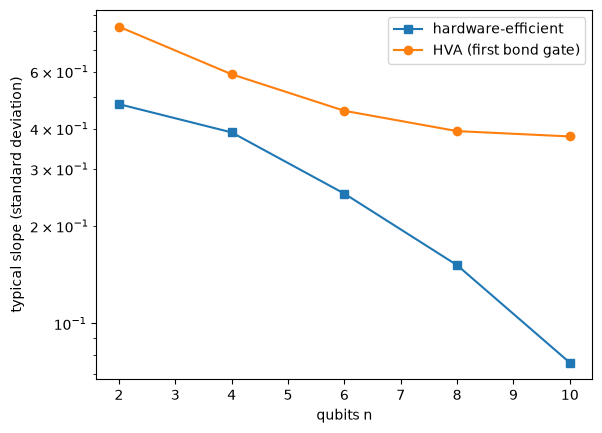

In [26]:
def slope_spread(circuit, ham, samples):
    """The standard deviation of dE/d(first parameter) of `circuit` at random angles, for the Hamiltonian `ham`."""
    slopes = []
    for _ in range(samples):
        angles = np.random.uniform(0, 2 * np.pi, circuit.num_parameters)
        # BEGIN SOLUTION
        plus = angles.copy()
        plus[0] += np.pi / 2
        minus = angles.copy()
        minus[0] -= np.pi / 2
        energy_plus = Statevector(circuit.assign_parameters(plus)).expectation_value(ham).real
        energy_minus = Statevector(circuit.assign_parameters(minus)).expectation_value(ham).real
        slopes.append((energy_plus - energy_minus) / 2)
        # END SOLUTION
    return np.std(slopes)


sizes = [2, 4, 6, 8, 10]
spread_hea, spread_hva = [], []
for size in sizes:
    ham = tfim(size, J, h)
    spread_hea.append(slope_spread(hardware_efficient_ansatz(size, 4 * size), ham, 100))
    circuit_per_gate, _ = hva_ansatz_per_gate(size, 4 * size)
    spread_hva.append(slope_spread(circuit_per_gate, ham, 100))
print("hardware-efficient:", np.round(spread_hea, 3))
print("HVA:               ", np.round(spread_hva, 3))

plt.semilogy(sizes, spread_hea, "s-", label="hardware-efficient")
plt.semilogy(sizes, spread_hva, "o-", label="HVA (first bond gate)")
plt.xlabel("qubits n")
plt.ylabel("typical slope (standard deviation)")
plt.legend()
plt.show()

<!-- BEGIN SOLUTION -->
**Solution.** The spread of the hardware-efficient ansatz falls from about 0.34 at 4 qubits to
about 0.09 at 10, by a factor of about 0.6 for every two qubits from 6 qubits on, as in the notes.
At that rate, a factor 100 takes about 9 more steps of two qubits ($0.6^9 \approx 0.01$), so about
28 qubits. Telling the sign of a slope $g$ needs a standard error below $g$, so a number of shots
that grows as $1/g^2$: $10^4$ times more shots. The HVA's spread falls too, but slowly, from about 0.8
at 2 qubits to about 0.4 at 10, with no sign of an exponential decay: this structured ansatz has no
barren plateau (notes, section ["Barren plateaus"](https://stefanopolla.github.io/course-testing/L4-ground-states.html#sec-barren-plateaus); recall also that the TFIM chain can be solved
classically).
<!-- END SOLUTION -->

## Wrap-up

- The adiabatic circuit prepares the ground state if its total time is long and its steps are
  short, but such circuits are deep. The HVA keeps its structure, with few layers, and lets an
  optimiser choose the angles.
- A parametrised circuit is built once, with `ParameterVector`, and `assign_parameters` fills in
  the angles; the energy is then a function of an array of angles, which scipy's `minimize` can
  optimise.
- With shots, the lowest estimate an optimiser has seen is biased low: estimate the energy at the
  final angles again, with fresh shots.
- COBYLA stops early once the shot noise hides the energy differences it compares. Gradient
  descent costs many more shots per step, but its noise averages out over the steps.
- Compare optimisers by the total number of shots they need for a given accuracy, not by their
  iterations.
- Gate noise raises the energy. More layers make a better ansatz but add noise, and the best number
  of layers balances the two.

Next week, we reduce the bias of Exercise 4 with error mitigation.